# Phase 3 - Feature Engineering for Udupi High-Wave Classification

Predict the experimental offshore category of `max(VHM0[t+3h], VHM0[t+6h])` using information available at or before t. This is **direct multiclass classification**, not regression.

Finalized categories: **Normal (0): below 2.5 m; Elevated / Watch (1): 2.5-3.0 m inclusive; High / Alert (2): above 3.0 m.** These are experimental research categories, not official operational warnings. No threshold alternatives are considered.

Run cells manually in order with the project `.venv` kernel. This notebook is delivered **unexecuted**. It reconstructs Phase 2 labels/splits, builds deterministic causal features and prepares six in-memory X/y objects. No files are exported, learned transforms fitted, classes balanced, classifiers trained or models evaluated.

## 1. Load and validate the original source

The relative path supports a kernel started from notebooks/ or the project root. No state from previous notebooks is required. Parse UTC, sort in memory and reject unexpected data rather than filling, clipping or dropping measurements. Units and meanings follow the repository's verified Copernicus documentation.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

data_path = Path("../data/udupi_wave_wind_2015_2024.csv")
if not data_path.is_file():
    data_path = Path("data/udupi_wave_wind_2015_2024.csv")
if not data_path.is_file():
    raise FileNotFoundError("Run from notebooks/ or the project root; the original CSV is required.")
source = pd.read_csv(data_path, float_precision="round_trip")
expected_columns = [
    "timestamp", "latitude", "longitude", "VHM0", "VHM0_SW1", "VHM0_SW2", "VHM0_WW",
    "VMDR", "VMDR_SW1", "VMDR_SW2", "VMDR_WW", "VTM01_SW1", "VTM01_SW2", "VTM01_WW",
    "VTM02", "VTM10", "VTPK", "eastward_wind", "northward_wind", "wind_speed",
]
if set(source.columns) != set(expected_columns) or source.shape != (29224, 20):
    raise ValueError("Source schema or size differs from completed Phase 2.")
source["timestamp"] = pd.to_datetime(source["timestamp"], utc=True, errors="raise")
if source["timestamp"].isna().any() or source["timestamp"].duplicated().any():
    raise ValueError("Missing or duplicate timestamps prevent reliable labels.")
source = source.sort_values("timestamp").set_index("timestamp")
source.index = source.index.as_unit("ns")
expected_index = pd.date_range("2015-01-01", "2024-12-31T21:00", freq="3h", tz="UTC").as_unit("ns")
if not source.index.equals(expected_index):
    raise ValueError("The regular three-hourly UTC grid is incomplete or changed.")
if not all(pd.api.types.is_numeric_dtype(source[c]) for c in source):
    raise ValueError("Source measurements must be numeric.")
if source.isna().any().any() or not np.isfinite(source.to_numpy()).all():
    raise ValueError("Missing/nonfinite source values require investigation; no filling is performed.")
height_period_columns = [c for c in source if c.startswith(("VHM", "VTM", "VTP"))]
direction_columns = [c for c in source if c.startswith("VMDR")]
if source[height_period_columns].lt(0).any().any() or any(not source[c].between(0, 360).all() for c in direction_columns):
    raise ValueError("Invalid heights, periods or directions require investigation.")
if len(source[["latitude", "longitude"]].drop_duplicates()) != 1 or not np.allclose(
    source[["latitude", "longitude"]].iloc[0], [13.399999618530273, 74.5999984741211], rtol=0, atol=1e-10
):
    raise ValueError("Unexpected reference coordinates.")
if source[["eastward_wind", "northward_wind"]].abs().gt(100).any().any() or not np.allclose(
    source["wind_speed"], np.hypot(source["eastward_wind"], source["northward_wind"]), rtol=1e-10, atol=1e-12
):
    raise ValueError("Wind validity or speed arithmetic differs from Phase 2.")
print(f"Validated {len(source):,} source rows: {source.index.min()} to {source.index.max()}; UTC, 3h, no missing values.")
display(source.head())

Validated 29,224 source rows: 2015-01-01 00:00:00+00:00 to 2024-12-31 21:00:00+00:00; UTC, 3h, no missing values.


,latitude,longitude,VHM0,VHM0_SW1,VHM0_SW2,VHM0_WW,VMDR,VMDR_SW1,VMDR_SW2,VMDR_WW,VTM01_SW1,VTM01_SW2,VTM01_WW,VTM02,VTM10,VTPK,eastward_wind,northward_wind,wind_speed
timestamp,,,,,,,,,,,,,,,,,,,
2015-01-01 00:00:00+00:00,13.4,74.599998,0.60,0.32,0.23,0.00,245.21,194.34,209.16,213.64,9.12,19.18,0.00,4.46,8.00,19.48,0.363307,0.706901,0.794796
2015-01-01 03:00:00+00:00,13.4,74.599998,0.57,0.31,0.26,0.00,239.12,193.46,209.12,145.02,8.96,18.49,0.00,4.66,8.62,19.02,0.563214,0.442098,0.716003
2015-01-01 06:00:00+00:00,13.4,74.599998,0.56,0.31,0.27,0.00,235.00,193.34,208.65,216.28,8.86,18.17,0.00,4.81,9.04,19.45,3.602809,0.997492,3.738345
2015-01-01 09:00:00+00:00,13.4,74.599998,0.57,0.30,0.29,0.15,233.51,211.54,189.86,249.71,16.71,9.40,1.85,4.29,8.99,19.07,4.851309,0.933394,4.940285
2015-01-01 12:00:00+00:00,13.4,74.599998,0.59,0.30,0.29,0.05,233.21,207.88,189.76,276.55,17.15,9.25,1.38,4.28,8.77,18.74,4.215613,-0.653205,4.265920


## 2. Reconstruct finalized integer classification labels

Negative shifts below are **only for outcomes**, never predictors. Check exact +3h/+6h timestamps, then require both future heights with skipna=False. Missing future values must not fall through to a valid class. Exactly 2.5 m and 3.0 m both belong to Elevated / Watch.

The future maximum is an intermediate label diagnostic, not a regression training target or the maximum individual wave during a continuously observed six-hour period. Future outcomes may define supervised labels but must never enter input features. Zero-valued absent partitions are preserved, consistent with Phase 2.

In [2]:
times = source.index.to_series()
exact_3h = times.shift(-1).eq(times + pd.Timedelta(hours=3))
exact_6h = times.shift(-2).eq(times + pd.Timedelta(hours=6))
if not exact_3h.iloc[:-1].all() or not exact_6h.iloc[:-2].all():
    raise ValueError("Shifted future rows are not exactly +3h/+6h.")
future_3h = source["VHM0"].shift(-1)
future_6h = source["VHM0"].shift(-2)
future_max_wave_height = pd.concat([future_3h, future_6h], axis=1).max(axis=1, skipna=False)
complete_horizon = exact_3h & exact_6h & future_max_wave_height.notna()
if not complete_horizon.iloc[:-2].all() or complete_horizon.iloc[-2:].any():
    raise ValueError("Unexpected incomplete horizons beyond the final two rows.")
target_class = pd.Series(pd.NA, index=source.index, dtype="Int64", name="target_class")
target_class.loc[complete_horizon] = np.select(
    [future_max_wave_height.loc[complete_horizon].lt(2.5), future_max_wave_height.loc[complete_horizon].le(3.0)],
    [0, 1], default=2,
)
labeled = pd.DataFrame({"future_max_wave_height": future_max_wave_height, "target_class": target_class}).loc[complete_horizon].copy()
labeled["target_class"] = labeled["target_class"].astype("int64")
if len(labeled) != 29222 or not target_class.iloc[-2:].isna().all():
    raise ValueError("Label count or missing-horizon handling differs from Phase 2.")
boundary_heights = np.array([2.49, 2.5, 3.0, 3.01])
boundary_classes = np.select([boundary_heights < 2.5, boundary_heights <= 3.0], [0, 1], default=2)
np.testing.assert_array_equal(boundary_classes, [0, 1, 1, 2])
display(pd.DataFrame({"boundary_height_m": boundary_heights, "class": boundary_classes}))
display(pd.DataFrame({"current_VHM0": source["VHM0"], "future_3h": future_3h, "future_6h": future_6h,
                      "future_max_wave_height": future_max_wave_height, "target_class": target_class}).head())
print("Complete horizons:", len(labeled), "; excluded final observations:", int((~complete_horizon).sum()))

,boundary_height_m,class
0,2.49,0
1,2.50,1
2,3.00,1
3,3.01,2


,current_VHM0,future_3h,future_6h,future_max_wave_height,target_class
timestamp,,,,,
2015-01-01 00:00:00+00:00,0.60,0.57,0.56,0.57,0
2015-01-01 03:00:00+00:00,0.57,0.56,0.57,0.57,0
2015-01-01 06:00:00+00:00,0.56,0.57,0.59,0.59,0
2015-01-01 09:00:00+00:00,0.57,0.59,0.60,0.60,0
2015-01-01 12:00:00+00:00,0.59,0.60,0.61,0.61,0


Complete horizons: 29222 ; excluded final observations: 2


## 3. Reproduce the exact chronological 70/10/20 boundaries

Match Phase 2: floor 70% and floor 10% of the complete-horizon rows, with the remainder for testing. Purge earlier-partition rows whose t+6h reaches the next nominal start. Compare dates/counts to the saved Phase 2 outputs below. Do not move boundaries after purging or historical-context exclusions.

Observations excluded as supervised rows still supply valid historical measurements. Validation/test features may use earlier known measurements, including immediately preceding their partition. Earlier labels cannot reach into the next partition. No shuffling occurs.

In [3]:
n_labeled = len(labeled)
validation_position = int(np.floor(0.70 * n_labeled))
test_position = validation_position + int(np.floor(0.10 * n_labeled))
nominal_partitions = {
    "Training": labeled.iloc[:validation_position].copy(),
    "Validation": labeled.iloc[validation_position:test_position].copy(),
    "Testing": labeled.iloc[test_position:].copy(),
}
next_starts = {"Training": nominal_partitions["Validation"].index[0], "Validation": nominal_partitions["Testing"].index[0]}
partitions = {}
for name, part in nominal_partitions.items():
    keep = (part.index + pd.Timedelta(hours=6) < next_starts[name]) if name in next_starts else np.ones(len(part), dtype=bool)
    partitions[name] = part.loc[keep].copy()
phase2_expected = {
    "Training": (20453, "2015-01-01T00:00", "2021-12-31T12:00"),
    "Validation": (2920, "2021-12-31T21:00", "2022-12-31T18:00"),
    "Testing": (5845, "2023-01-01T03:00", "2024-12-31T15:00"),
}
split_rows = []
for name, part in partitions.items():
    count, start, end = phase2_expected[name]
    if len(part) != count or part.index[0] != pd.Timestamp(start, tz="UTC") or part.index[-1] != pd.Timestamp(end, tz="UTC"):
        raise ValueError(f"{name} differs from completed Phase 2.")
    if name in next_starts and not (part.index + pd.Timedelta(hours=6) < next_starts[name]).all():
        raise ValueError(f"{name} labels cross the next boundary.")
    split_rows.append({"partition": name, "nominal_rows": len(nominal_partitions[name]), "Phase_2_rows": len(part),
                       "boundary_excluded": len(nominal_partitions[name]) - len(part), "start_UTC": part.index[0], "end_UTC": part.index[-1]})
split_summary = pd.DataFrame(split_rows).set_index("partition")
if split_summary["boundary_excluded"].sum() != 4:
    raise ValueError("Expected four label-boundary exclusions.")
display(split_summary)

,nominal_rows,Phase_2_rows,boundary_excluded,start_UTC,end_UTC
partition,,,,,
Training,20455,20453,2,2015-01-01 00:00:00+00:00,2021-12-31 12:00:00+00:00
Validation,2922,2920,2,2021-12-31 21:00:00+00:00,2022-12-31 18:00:00+00:00
Testing,5845,5845,0,2023-01-01 03:00:00+00:00,2024-12-31 15:00:00+00:00


## 4. Select meaningful current measurements and direction information

Retain 13 measurements: four heights, six periods and three wind quantities. Four wave from-directions will become eight sine/cosine inputs. Coordinates are constant metadata; identifiers and raw year/month are excluded. Raw degrees are not inputs because 0 and 360 represent the same direction.

Speed is derived from U/V, but not an identical duplicate: speed supplies magnitude explicitly while signed components retain orientation. Keeping all three can help tree models; they remain dependent, which warrants care when interpreting linear-model coefficients. No learned feature selection is performed. The CSV has no wind-direction angle column; U/V already preserve wind orientation, so no extra angle is invented.

In [4]:
current_features = {
    "VHM0": ("m", "Total significant wave height"),
    "VHM0_SW1": ("m", "Primary swell significant height"),
    "VHM0_SW2": ("m", "Secondary swell significant height"),
    "VHM0_WW": ("m", "Wind-wave significant height"),
    "VTM01_SW1": ("s", "Primary swell mean period, moments (0, 1)"),
    "VTM01_SW2": ("s", "Secondary swell mean period, moments (0, 1)"),
    "VTM01_WW": ("s", "Wind-wave mean period, moments (0, 1)"),
    "VTM02": ("s", "Total mean period, moments (0, 2)"),
    "VTM10": ("s", "Total period, moments (-1, 0)"),
    "VTPK": ("s", "Peak wave period"),
    "eastward_wind": ("m/s", "Interpolated stress-equivalent 10 m eastward wind"),
    "northward_wind": ("m/s", "Interpolated stress-equivalent 10 m northward wind"),
    "wind_speed": ("m/s", "Magnitude of interpolated wind components"),
}
directions = {"VMDR": "Total wave from-direction", "VMDR_SW1": "Primary swell from-direction",
              "VMDR_SW2": "Secondary swell from-direction", "VMDR_WW": "Wind-wave from-direction"}
original_description = pd.DataFrame([
    {"column": c, "units": unit, "meaning": meaning, "representation": "Current numeric value"}
    for c, (unit, meaning) in current_features.items()
] + [{"column": c, "units": "degrees clockwise from north", "meaning": meaning, "representation": "Sine/cosine instead of raw degrees"}
     for c, meaning in directions.items()])
display(original_description)
training_source = source.loc[partitions["Training"].index]
constant_original_columns = training_source.columns[training_source.nunique(dropna=False).le(1)].tolist()
print("Constant source columns in training (excluded metadata):", constant_original_columns)
if set(constant_original_columns).intersection(set(current_features) | set(directions)):
    raise ValueError("A selected measurement is constant in training; review before proceeding.")
identical_measurements = training_source[list(current_features) + list(directions)].T.duplicated()
if identical_measurements.any():
    raise ValueError(f"Identical measurements require review: {identical_measurements[identical_measurements].index.tolist()}")

,column,units,meaning,representation
0,VHM0,m,Total significant wave height,Current numeric value
1,VHM0_SW1,m,Primary swell significant height,Current numeric value
2,VHM0_SW2,m,Secondary swell significant height,Current numeric value
3,VHM0_WW,m,Wind-wave significant height,Current numeric value
4,VTM01_SW1,s,"Primary swell mean period, moments (0, 1)",Current numeric value
5,VTM01_SW2,s,"Secondary swell mean period, moments (0, 1)",Current numeric value
6,VTM01_WW,s,"Wind-wave mean period, moments (0, 1)",Current numeric value
7,VTM02,s,"Total mean period, moments (0, 2)",Current numeric value
8,VTM10,s,"Total period, moments (-1, 0)",Current numeric value
9,VTPK,s,Peak wave period,Current numeric value


Constant source columns in training (excluded metadata): ['latitude', 'longitude']


## 5. Specify a compact causal feature set

- **Lags:** VHM0 at 3/6/12/24 hours; wind speed at 3/6/12 hours; primary swell height at 6 hours; VTM02 at 3 hours. The two extra lags add limited swell/period memory without dozens of similar variables.
- **Changes:** current minus earlier VHM0 at 3/6/12 hours and speed at 3/6 hours. Positive means rising. These are differences in original units, not rates per hour. No potentially unstable percentage changes are added.
- **Rolling:** VHM0 means at 6/12/24 hours, maxima at 12/24 hours, standard deviation at 12 hours; speed means at 6/12 hours and maximum at 12 hours. These wind histories use the **three-hourly CSV**, not the original hourly wind series.
- **Seasonality:** extract UTC month and use its sine/cosine only. December/January remain adjacent. No raw month, year or extra day-of-year inputs are included.
- **Direction:** sine/cosine of each varying wave from-direction. Raw degree columns are replaced. Zero-height partitions may have weak directional meaning; retain partition heights as context rather than silently altering source directions.

All rolling windows are trailing, including the current observation. A window of N observations starts at t-3*(N-1) hours: **8 observations span t-21h through t**, not eight previous observations plus current. Six-hour and 12-hour windows contain 2 and 4 observations. Require min_periods=N and use sample standard deviation (ddof=1). No centered windows.

In [5]:
lag_hours = {"VHM0": (3, 6, 12, 24), "wind_speed": (3, 6, 12), "VHM0_SW1": (6,), "VTM02": (3,)}
change_hours = {"VHM0": (3, 6, 12), "wind_speed": (3, 6)}
rolling_specs = [
    ("VHM0", "mean", 6), ("VHM0", "mean", 12), ("VHM0", "mean", 24),
    ("VHM0", "max", 12), ("VHM0", "max", 24), ("VHM0", "std", 12),
    ("wind_speed", "mean", 6), ("wind_speed", "mean", 12), ("wind_speed", "max", 12),
]
if any(hours <= 0 or hours % 3 for specs in (lag_hours, change_hours) for values in specs.values() for hours in values):
    raise ValueError("Feature lags must use positive multiples of three hours.")
if any(hours < 6 or hours % 3 for _, _, hours in rolling_specs):
    raise ValueError("Rolling windows require at least two regular observations.")

# One deterministic function, also used by the future-perturbation check.
# Input contains only original measurements and timestamps, never labels.
def make_features(measurements):
    result = measurements[list(current_features)].copy()
    for column in directions:
        radians = np.deg2rad(measurements[column])
        result[f"{column}_sin"] = np.sin(radians)
        result[f"{column}_cos"] = np.cos(radians)
    for column, hours_list in lag_hours.items():
        for hours in hours_list:
            result[f"{column}_lag_{hours}h"] = measurements[column].shift(hours // 3)
    for column, hours_list in change_hours.items():
        for hours in hours_list:
            result[f"{column}_change_{hours}h"] = measurements[column] - measurements[column].shift(hours // 3)
    for column, statistic, hours in rolling_specs:
        window = measurements[column].rolling(window=hours // 3, min_periods=hours // 3, center=False)
        result[f"{column}_roll_{statistic}_{hours}h"] = window.std(ddof=1) if statistic == "std" else getattr(window, statistic)()
    month = measurements.index.month
    result["month_sin"] = np.sin(2 * np.pi * month / 12)
    result["month_cos"] = np.cos(2 * np.pi * month / 12)
    return result

# Build history over the full chronology before selecting partition rows.
features = make_features(source)
print("Number of input features:", len(features.columns))

Number of input features: 46


## 6. Final input dictionary and preview

Every input has an explicit description and units. There is no automatic learned feature selection or duplicate raw direction representation. Coordinates and raw timestamp remain metadata. No label or future quantity enters this dictionary.

In [6]:
feature_rows = [{"feature": column, "group": "Current measurements", "units": unit, "description": meaning + " at t"}
                for column, (unit, meaning) in current_features.items()]
for column, meaning in directions.items():
    for encoding in ("sin", "cos"):
        feature_rows.append({"feature": f"{column}_{encoding}", "group": "Direction encoding", "units": "unitless",
                             "description": f"{encoding}({meaning} in radians) at t"})
for column, hours_list in lag_hours.items():
    for hours in hours_list:
        feature_rows.append({"feature": f"{column}_lag_{hours}h", "group": "Historical lags", "units": current_features[column][0],
                             "description": f"{column} observed at t-{hours}h"})
for column, hours_list in change_hours.items():
    for hours in hours_list:
        feature_rows.append({"feature": f"{column}_change_{hours}h", "group": "Changes", "units": current_features[column][0],
                             "description": f"{column}(t) minus {column}(t-{hours}h)"})
for column, statistic, hours in rolling_specs:
    feature_rows.append({"feature": f"{column}_roll_{statistic}_{hours}h", "group": "Trailing statistics", "units": current_features[column][0],
                         "description": f"{statistic} of {hours // 3} observations from t-{hours - 3}h through t (inclusive)"})
for encoding in ("sin", "cos"):
    feature_rows.append({"feature": f"month_{encoding}", "group": "Seasonality", "units": "unitless",
                         "description": f"{encoding}(2*pi*UTC month/12)"})
feature_dictionary = pd.DataFrame(feature_rows).set_index("feature")
if feature_dictionary.index.tolist() != features.columns.tolist() or len(features.columns) != 46:
    raise ValueError("Feature dictionary does not match the intended 46 inputs.")
display(feature_dictionary)
display(feature_dictionary.groupby("group", sort=False).size().to_frame("input_count"))
display(features.head(10))

,group,units,description
feature,,,
VHM0,Current measurements,m,Total significant wave height at t
VHM0_SW1,Current measurements,m,Primary swell significant height at t
VHM0_SW2,Current measurements,m,Secondary swell significant height at t
VHM0_WW,Current measurements,m,Wind-wave significant height at t
VTM01_SW1,Current measurements,s,"Primary swell mean period, moments (0, 1) at t"
VTM01_SW2,Current measurements,s,"Secondary swell mean period, moments (0, 1) at t"
VTM01_WW,Current measurements,s,"Wind-wave mean period, moments (0, 1) at t"
VTM02,Current measurements,s,"Total mean period, moments (0, 2) at t"
VTM10,Current measurements,s,"Total period, moments (-1, 0) at t"


,input_count
group,
Current measurements,13
Direction encoding,8
Historical lags,9
Changes,5
Trailing statistics,9
Seasonality,2


,VHM0,VHM0_SW1,VHM0_SW2,VHM0_WW,VTM01_SW1,VTM01_SW2,VTM01_WW,VTM02,VTM10,VTPK,...,VHM0_roll_mean_12h,VHM0_roll_mean_24h,VHM0_roll_max_12h,VHM0_roll_max_24h,VHM0_roll_std_12h,wind_speed_roll_mean_6h,wind_speed_roll_mean_12h,wind_speed_roll_max_12h,month_sin,month_cos
timestamp,,,,,,,,,,,,,,,,,,,,,
2015-01-01 00:00:00+00:00,0.60,0.32,0.23,0.00,9.12,19.18,0.00,4.46,8.00,19.48,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.5,0.866025
2015-01-01 03:00:00+00:00,0.57,0.31,0.26,0.00,8.96,18.49,0.00,4.66,8.62,19.02,...,NaN,NaN,NaN,NaN,NaN,0.755400,NaN,NaN,0.5,0.866025
2015-01-01 06:00:00+00:00,0.56,0.31,0.27,0.00,8.86,18.17,0.00,4.81,9.04,19.45,...,NaN,NaN,NaN,NaN,NaN,2.227174,NaN,NaN,0.5,0.866025
2015-01-01 09:00:00+00:00,0.57,0.30,0.29,0.15,16.71,9.40,1.85,4.29,8.99,19.07,...,0.5750,NaN,0.60,NaN,0.017321,4.339315,2.547357,4.940285,0.5,0.866025
2015-01-01 12:00:00+00:00,0.59,0.30,0.29,0.05,17.15,9.25,1.38,4.28,8.77,18.74,...,0.5725,NaN,0.59,NaN,0.012583,4.603103,3.415138,4.940285,0.5,0.866025
2015-01-01 15:00:00+00:00,0.60,0.33,0.28,0.00,15.77,8.88,0.00,4.42,8.81,18.62,...,0.5800,NaN,0.60,NaN,0.018257,3.263448,3.801382,4.940285,0.5,0.866025
2015-01-01 18:00:00+00:00,0.61,0.34,0.28,0.00,15.73,8.83,0.00,4.63,9.00,18.35,...,0.5925,NaN,0.61,NaN,0.017078,1.777654,3.190378,4.940285,0.5,0.866025
2015-01-01 21:00:00+00:00,0.61,0.35,0.28,0.00,15.56,8.79,0.00,4.87,9.24,17.98,...,0.6025,0.58875,0.61,0.61,0.009574,0.996731,2.130090,4.265920,0.5,0.866025
2015-01-02 00:00:00+00:00,0.60,0.35,0.28,0.00,15.31,8.76,0.00,5.13,9.43,17.55,...,0.6050,0.58875,0.61,0.61,0.005774,1.447112,1.612383,2.260977,0.5,0.866025


## 7. Remove incomplete history without moving partition boundaries

The 24-hour lag requires eight earlier rows. Exactly the first eight source rows should therefore lack historical features; the first complete timestamp is **2015-01-02 00:00 UTC**. The 8-observation rolling window becomes complete after seven earlier rows, but the 24-hour lag sets the common start.

Do not fill missing lags with zero or backward fill. Reject unrelated missingness rather than silently discarding it. Apply completeness within the existing Phase 2 partitions, never recalculate the split after dropping rows. Validation/test history may include any genuinely available earlier source measurements, including those purged as supervised boundary rows.

In [7]:
feature_incomplete = features.isna().any(axis=1)
if not features.index[feature_incomplete].equals(source.index[:8]):
    raise ValueError("Unexpected feature missingness outside the first eight historical-context rows.")
first_complete_time = features.index[~feature_incomplete][0]
print("First timestamp with all selected features:", first_complete_time)
display(features.isna().sum().loc[lambda counts: counts.gt(0)].to_frame("initial_missing_count"))
model_partitions = {}
history_rows = []
for name, part in partitions.items():
    retained = part.loc[~feature_incomplete.reindex(part.index)].copy()
    model_partitions[name] = retained
    removed = len(part) - len(retained)
    if removed != (8 if name == "Training" else 0):
        raise ValueError(f"Unexpected historical-context exclusions in {name}.")
    history_rows.append({"partition": name, "Phase_2_rows": len(part), "feature_incomplete_removed": removed,
                         "retained_rows": len(retained), "first_usable_timestamp": retained.index[0],
                         "last_usable_timestamp": retained.index[-1]})
history_summary = pd.DataFrame(history_rows).set_index("partition")
display(history_summary)

First timestamp with all selected features: 2015-01-02 00:00:00+00:00


,initial_missing_count
VHM0_lag_3h,1
VHM0_lag_6h,2
VHM0_lag_12h,4
VHM0_lag_24h,8
wind_speed_lag_3h,1
wind_speed_lag_6h,2
wind_speed_lag_12h,4
VHM0_SW1_lag_6h,2
VTM02_lag_3h,1
VHM0_change_3h,1


,Phase_2_rows,feature_incomplete_removed,retained_rows,first_usable_timestamp,last_usable_timestamp
partition,,,,,
Training,20453,8,20445,2015-01-02 00:00:00+00:00,2021-12-31 12:00:00+00:00
Validation,2920,0,2920,2021-12-31 21:00:00+00:00,2022-12-31 18:00:00+00:00
Testing,5845,0,5845,2023-01-01 03:00:00+00:00,2024-12-31 15:00:00+00:00


## 8. Explicit leakage checks

Feature shifts are positive, rolling windows are trailing and their requirements are explicit. Only original measurements feed make_features; future diagnostics and classes remain isolated. Split dates/membership must remain those from Phase 2 after the documented exclusions. No learned transforms, scaling, normalization, class weighting, balancing or SMOTE are used.

The causal perturbation test changes only a temporary copy of measurements **after** a cutoff and requires every earlier feature to remain identical. It exercises a year boundary; the altered data are never used in model-ready inputs and do not change the CSV.

In [8]:
forbidden_columns = {"future_max_wave_height", "future_3h", "future_6h", "target_class", "timestamp", "latitude", "longitude", "month", "year"}
if forbidden_columns.intersection(features.columns) or any(c.startswith(("future_", "target_")) for c in features):
    raise ValueError("Future-derived or metadata columns entered the predictors.")
if set(directions).intersection(features.columns):
    raise ValueError("Raw directions should have been replaced with circular encodings.")
for column, hours_list in lag_hours.items():
    for hours in hours_list:
        pd.testing.assert_series_equal(features[f"{column}_lag_{hours}h"], source[column].shift(hours // 3), check_names=False)
for column, statistic, hours in rolling_specs:
    window = source[column].rolling(hours // 3, min_periods=hours // 3, center=False)
    expected = window.std(ddof=1) if statistic == "std" else getattr(window, statistic)()
    pd.testing.assert_series_equal(features[f"{column}_roll_{statistic}_{hours}h"], expected, check_names=False)

cutoff = pd.Timestamp("2022-01-01T00:00", tz="UTC")
perturbed_source = source.copy()
perturb_columns = list(current_features) + list(directions)
perturbed_source.loc[perturbed_source.index > cutoff, perturb_columns] *= 1.25
perturbed_features = make_features(perturbed_source)
pd.testing.assert_frame_equal(features.loc[:cutoff], perturbed_features.loc[:cutoff])
for name, part in model_partitions.items():
    if name in next_starts and not (part.index + pd.Timedelta(hours=6) < next_starts[name]).all():
        raise ValueError("Labels cross an unchanged nominal boundary.")
    if not part.index.isin(partitions[name].index).all():
        raise ValueError("Model-ready rows left their Phase 2 partition.")
if model_partitions["Validation"].index[0] != partitions["Validation"].index[0] or model_partitions["Testing"].index[0] != partitions["Testing"].index[0]:
    raise ValueError("Validation/test boundaries changed.")
del perturbed_source, perturbed_features
print("Leakage checks passed: historical shifts, trailing windows, forbidden inputs, causal prefix invariance and fixed partitions.")
print("No learned preprocessing or class balancing has been fitted.")

Leakage checks passed: historical shifts, trailing windows, forbidden inputs, causal prefix invariance and fixed partitions.
No learned preprocessing or class balancing has been fitted.


## 9. Build the six model-ready X/y objects

All X matrices use identical ordered numeric columns and UTC timestamp indices. Labels are integers 0/1/2. The future maximum stays in a separate diagnostic frame, never X. No feature scaling or normalization is performed. Future learned transforms must be fitted on training only.

In [9]:
input_features = features.columns.tolist()
X_train = features.loc[model_partitions["Training"].index, input_features].copy()
y_train = model_partitions["Training"]["target_class"].astype("int64").copy()
X_val = features.loc[model_partitions["Validation"].index, input_features].copy()
y_val = model_partitions["Validation"]["target_class"].astype("int64").copy()
X_test = features.loc[model_partitions["Testing"].index, input_features].copy()
y_test = model_partitions["Testing"]["target_class"].astype("int64").copy()
for name, X, y in [("Training", X_train, y_train), ("Validation", X_val, y_val), ("Testing", X_test, y_test)]:
    if not X.index.equals(y.index) or not X.index.is_monotonic_increasing or X.index.has_duplicates:
        raise ValueError(f"{name} input/label alignment is invalid.")
    if X.columns.tolist() != input_features or not all(pd.api.types.is_numeric_dtype(X[c]) for c in X):
        raise ValueError(f"{name} input schema is invalid.")
    if not np.isfinite(X.to_numpy()).all() or not y.isin([0, 1, 2]).all():
        raise ValueError(f"{name} contains missing/nonfinite inputs or invalid labels.")
shapes = pd.DataFrame([
    {"object": "X_train", "shape": X_train.shape}, {"object": "y_train", "shape": y_train.shape},
    {"object": "X_val", "shape": X_val.shape}, {"object": "y_val", "shape": y_val.shape},
    {"object": "X_test", "shape": X_test.shape}, {"object": "y_test", "shape": y_test.shape},
]).set_index("object")
expected_shapes = ((20445, 46), (20445,), (2920, 46), (2920,), (5845, 46), (5845,))
if tuple(shapes["shape"]) != expected_shapes:
    raise ValueError("Shapes disagree with the intended features and unchanged Phase 2 split.")
display(shapes)
print("Total model-ready observations:", len(X_train) + len(X_val) + len(X_test))
display(X_train.head())

,shape
object,
X_train,"(20445, 46)"
y_train,"(20445,)"
X_val,"(2920, 46)"
y_val,"(2920,)"
X_test,"(5845, 46)"
y_test,"(5845,)"


Total model-ready observations: 29210


,VHM0,VHM0_SW1,VHM0_SW2,VHM0_WW,VTM01_SW1,VTM01_SW2,VTM01_WW,VTM02,VTM10,VTPK,...,VHM0_roll_mean_12h,VHM0_roll_mean_24h,VHM0_roll_max_12h,VHM0_roll_max_24h,VHM0_roll_std_12h,wind_speed_roll_mean_6h,wind_speed_roll_mean_12h,wind_speed_roll_max_12h,month_sin,month_cos
timestamp,,,,,,,,,,,,,,,,,,,,,
2015-01-02 00:00:00+00:00,0.60,0.35,0.28,0.00,15.31,8.76,0.00,5.13,9.43,17.55,...,0.6050,0.58875,0.61,0.61,0.005774,1.447112,1.612383,2.260977,0.5,0.866025
2015-01-02 03:00:00+00:00,0.59,0.35,0.28,0.00,15.06,8.79,0.00,5.37,9.53,17.16,...,0.6025,0.59125,0.61,0.61,0.009574,2.369733,1.683232,2.544372,0.5,0.866025
2015-01-02 06:00:00+00:00,0.59,0.36,0.27,0.00,14.57,8.75,0.00,5.62,9.59,16.74,...,0.5975,0.59500,0.61,0.61,0.009574,2.639787,2.043449,2.735202,0.5,0.866025
2015-01-02 09:00:00+00:00,0.60,0.36,0.27,0.02,14.83,8.44,1.46,5.81,9.58,16.37,...,0.5950,0.59875,0.60,0.61,0.005774,3.193495,2.781614,3.651788,0.5,0.866025
2015-01-02 12:00:00+00:00,0.64,0.39,0.30,0.00,14.45,9.00,0.00,6.13,9.71,16.51,...,0.6050,0.60500,0.64,0.64,0.023805,3.029098,2.834442,3.651788,0.5,0.866025


In [10]:
category_names = {0: "Normal", 1: "Elevated / Watch", 2: "High / Alert"}
class_rows = []
for name, labels in [("Training", y_train), ("Validation", y_val), ("Testing", y_test)]:
    counts = labels.value_counts().reindex([0, 1, 2], fill_value=0)
    for number, count in counts.items():
        class_rows.append({"partition": name, "class": number, "category": category_names[number],
                           "count": int(count), "percent_within_partition": count / len(labels) * 100})
display(pd.DataFrame(class_rows).set_index(["partition", "class", "category"]))
print("Validation/test counts are diagnostic only, not grounds for selecting features or changing thresholds.")

count  percent_within_partition
partition  class category                                         
Training   0     Normal            19023                 93.044754
           1     Elevated / Watch    872                  4.265101
           2     High / Alert        550                  2.690144
Validation 0     Normal             2674                 91.575342
           1     Elevated / Watch    153                  5.239726
           2     High / Alert         93                  3.184932
Testing    0     Normal             5448                 93.207870
           1     Elevated / Watch    275                  4.704876
           2     High / Alert        122                  2.087254

Validation/test counts are diagnostic only, not grounds for selecting features or changing thresholds.


## 10. Focused training-only visualizations

The heatmap uses a predeclared manageable subset of **training inputs only**. Correlation is descriptive, not predictive importance or an automatic feature-selection rule. Related heights, lags and rolling summaries are expected to correlate; no feature is removed based on this plot.

The time-series example uses a fixed two-week training window in June 2020, illustrating monsoon-period history and changes without selecting a test event. Figures appear inline; no files are saved.

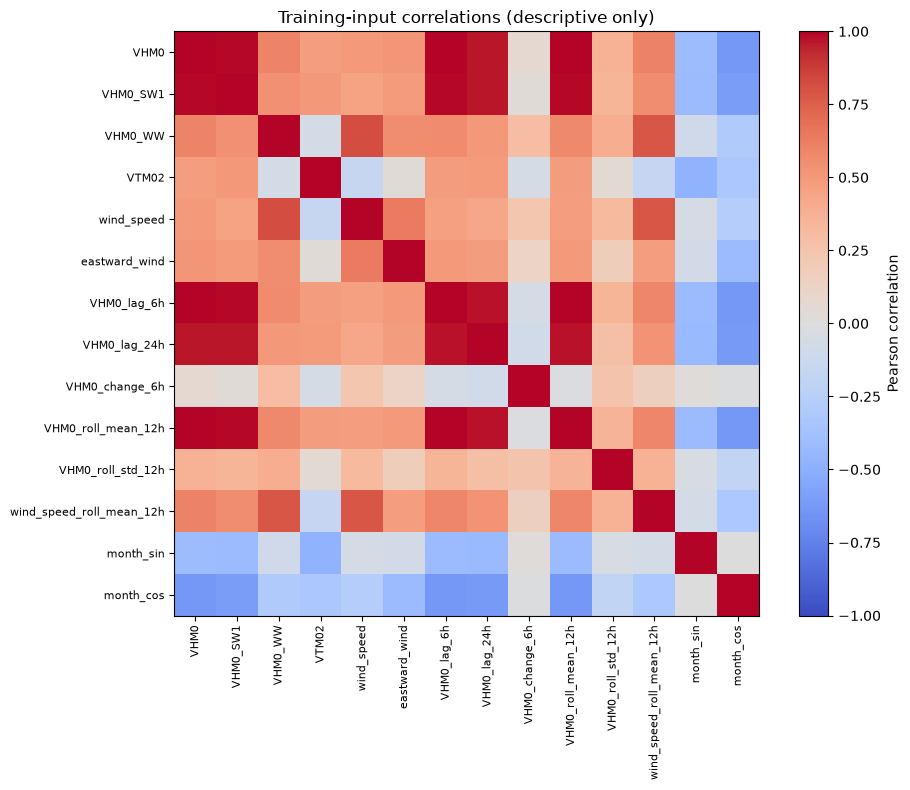

In [11]:
correlation_features = [
    "VHM0", "VHM0_SW1", "VHM0_WW", "VTM02", "wind_speed", "eastward_wind",
    "VHM0_lag_6h", "VHM0_lag_24h", "VHM0_change_6h", "VHM0_roll_mean_12h",
    "VHM0_roll_std_12h", "wind_speed_roll_mean_12h", "month_sin", "month_cos",
]
corr = X_train[correlation_features].corr()
fig, ax = plt.subplots(figsize=(10, 8))
image = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(corr.index)), corr.index, fontsize=8)
ax.set_title("Training-input correlations (descriptive only)")
fig.colorbar(image, ax=ax, label="Pearson correlation")
fig.tight_layout()
plt.show()

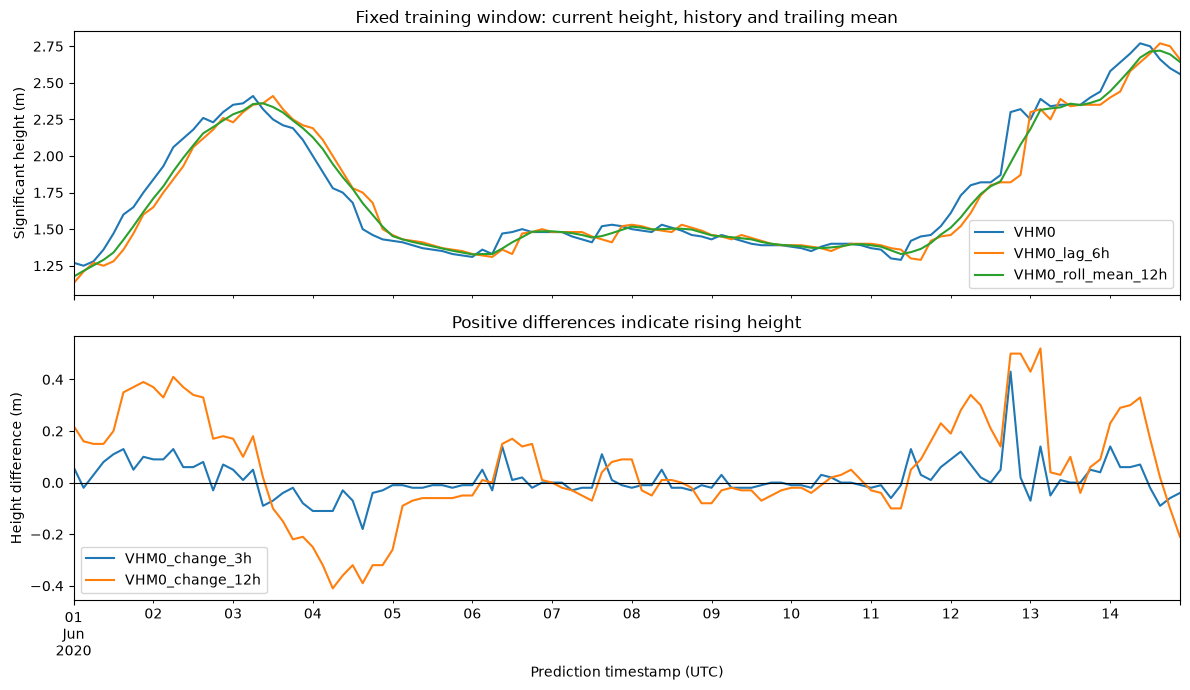

In [12]:
window = X_train.loc["2020-06-01":"2020-06-14"]
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
window[["VHM0", "VHM0_lag_6h", "VHM0_roll_mean_12h"]].plot(ax=axes[0])
axes[0].set(title="Fixed training window: current height, history and trailing mean", ylabel="Significant height (m)")
window[["VHM0_change_3h", "VHM0_change_12h"]].plot(ax=axes[1])
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set(title="Positive differences indicate rising height", ylabel="Height difference (m)", xlabel="Prediction timestamp (UTC)")
fig.tight_layout()
plt.show()

## 11. Review and handoff to Phase 4

The following cell reports findings only after you execute this notebook. Expected outputs are 46 inputs, eight initial training-history exclusions and no validation/test-history exclusions. The source CSV and completed notebooks remain unchanged.

Jupyter notebooks do not automatically share variables. Phase 4 must **reproduce the same deterministic loading, label, split, feature specifications and make_features logic**, including integrity checks, rather than assuming X_train exists in a fresh kernel. No cross-notebook execution mechanism or serialized intermediate is introduced here. We will decide how to share the pipeline in Phase 4 before implementing training.

In [13]:
display(Markdown(f"""
### Phase 3 findings

- Final classes: Normal below 2.5 m, Elevated / Watch from 2.5 through 3.0 m inclusive, High / Alert above 3.0 m. Direct multiclass classification only.
- Phase 2 reproduced: {len(labeled):,} complete horizons and four internal label-boundary exclusions.
- Inputs: {len(input_features)} (13 current measurements, 8 direction encodings, 9 lags, 5 changes, 9 rolling statistics, 2 month encodings).
- First complete context: {first_complete_time}. Removed {int(history_summary.loc['Training', 'feature_incomplete_removed'])} initial training rows; no validation/test history loss.
- Final matrices: X_train {X_train.shape}, X_val {X_val.shape}, X_test {X_test.shape}; integer y vectors have matching timestamps.
- No future inputs, changed nominal cutoffs, fitted transforms, class balancing, trained models or exported intermediate files.
- Review before Phase 4: interpretability and redundancy of the selected features, plus the deterministic notebook handoff method. Thresholds remain finalized and unchanged.
"""))


### Phase 3 findings

- Final classes: Normal below 2.5 m, Elevated / Watch from 2.5 through 3.0 m inclusive, High / Alert above 3.0 m. Direct multiclass classification only.
- Phase 2 reproduced: 29,222 complete horizons and four internal label-boundary exclusions.
- Inputs: 46 (13 current measurements, 8 direction encodings, 9 lags, 5 changes, 9 rolling statistics, 2 month encodings).
- First complete context: 2015-01-02 00:00:00+00:00. Removed 8 initial training rows; no validation/test history loss.
- Final matrices: X_train (20445, 46), X_val (2920, 46), X_test (5845, 46); integer y vectors have matching timestamps.
- No future inputs, changed nominal cutoffs, fitted transforms, class balancing, trained models or exported intermediate files.
- Review before Phase 4: interpretability and redundancy of the selected features, plus the deterministic notebook handoff method. Thresholds remain finalized and unchanged.


## Stop before model training

Inspect the outputs manually before proceeding. No model scores exist. Phase 4 will address appropriate training-only transforms, imbalance handling and validation-based classifier fitting; Phase 5 will handle evaluation. Neither notebook is implemented by this phase.